In [ ]:
# https://archive-api.open-meteo.com/v1/archive?latitude=19.0760&longitude=72.8777&start_date=2026-11-01&end_date=2026-11-14&daily=temperature_2m_mean%2Ctemperature_2m_max%2Ctemperature_2m_min%2Cprecipitation_sum%2Cwind_speed_10m_max&timezone=Asia%2FKolkata


In [ ]:
import xarray as xr

# load gridded IMD data
ds = xr.open_dataset("/content/RF25_ind2024_rfp25.nc")

# pick a city (e.g., Mumbai lat/lon ~ 19.07N, 72.87E)
lat, lon = 19.07, 72.87

# find nearest grid point
city_rain = ds['rainfall'].sel(latitude=lat, longitude=lon, method='nearest')
city_rain.to_pandas().plot()


/usr/local/lib/python3.12/dist-packages/xarray/coding/times.py:213: SerializationWarning: Ambiguous reference date string: 1-1-1 00:00:00. The first value is assumed to be the year hence will be padded with zeros to remove the ambiguity (the padded reference date string is: 0001-1-1 00:00:00). To remove this message, remove the ambiguity by padding your reference date strings with zeros.
  ref_date = _ensure_padded_year(ref_date)


ValueError: Failed to decode variable 'time': unable to decode time units 'hours since 1-1-1 00:00:00' with "calendar 'standard'". Try opening your dataset with decode_times=False or installing cftime if it is not installed.

In [ ]:
!pip install cftime netCDF4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 100.6 MB/s eta 0:00:00


/usr/local/lib/python3.12/dist-packages/xarray/coding/times.py:213: SerializationWarning: Ambiguous reference date string: 1-1-1 00:00:00. The first value is assumed to be the year hence will be padded with zeros to remove the ambiguity (the padded reference date string is: 0001-1-1 00:00:00). To remove this message, remove the ambiguity by padding your reference date strings with zeros.
  ref_date = _ensure_padded_year(ref_date)


<Axes: xlabel='time'>

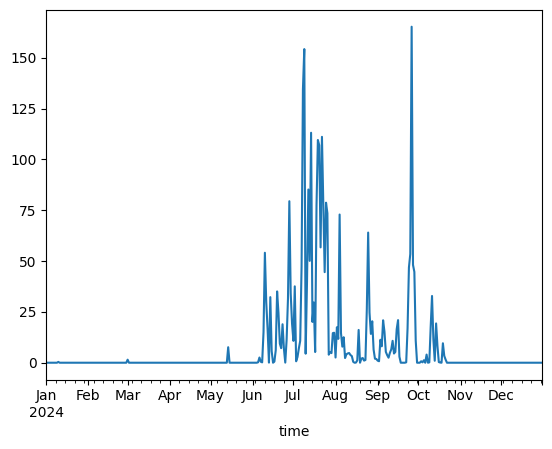

In [ ]:
import xarray as xr

# load gridded IMD data
ds = xr.open_dataset("/content/RF25_ind2024_rfp25.nc")

# pick a city (e.g., Mumbai lat/lon ~ 19.07N, 72.87E)
lat, lon = 19.07, 72.87

# find nearest grid point
city_rain = ds['rf'].sel(lat=lat, lon=lon, method='nearest')
city_rain.to_pandas().plot()

In [ ]:
import pandas as pd

df = city_rain.to_pandas()
display(df)

,rf
time,
2024-01-01,0.0
2024-01-02,0.0
2024-01-03,0.0
2024-01-04,0.0
2024-01-05,0.0
...,...
2024-12-27,0.0
2024-12-28,0.0
2024-12-29,0.0


In [ ]:
df["date"] =df.index


In [ ]:
df = df.reset_index()
display(df.head())

,time,rf
0,2024-01-01 00:00:00,0.0
1,2024-01-02 00:00:00,0.0
2,2024-01-03 00:00:00,0.0
3,2024-01-04 00:00:00,0.0
4,2024-01-05 00:00:00,0.0


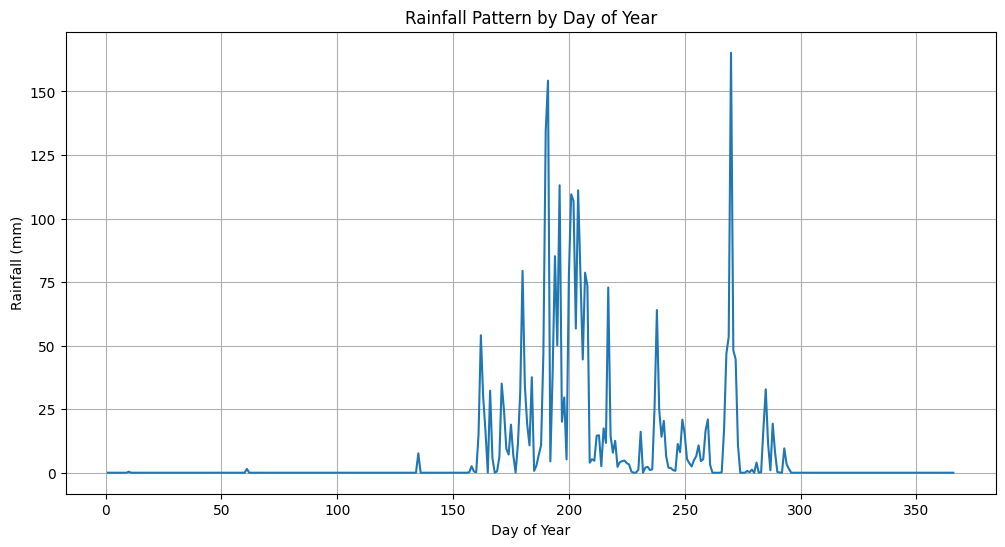

In [ ]:
curl -X 'GET' \
  'https://api.data.gov.in/resource/6c05cd1b-ed59-40c2-bc31-e314f39c6971?api-key=579b464db66ec23bdd000001cdd3946e44ce4aad7209ff7b23ac571b&format=csv&filters%5BYear%5D=2023&filters%5BState%5D=Goa' \
  -H 'accept: application/json'

SyntaxError: invalid syntax (ipython-input-2593452184.py, line 1)

In [ ]:
states =states = [
    "Andaman & Nicobar",
    "Andhra Pradesh",
    "Arunachal Pradesh",
    "Assam",
    "Bihar",
    "Chandigarh",
    "Chhattisgarh",
    "Dadra & Nagar Haveli",
    "Daman & Diu",
    "Delhi",
    "Goa",
    "Gujarat",
    "Haryana",
    "Himachal Pradesh",
    "Jammu & Kashmir",
    "Jharkhand",
    "Karnataka",
    "Kerala",
    "Ladakh",
    "Lakshadweep",
    "Madhya Pradesh",
    "Maharashtra",
    "Manipur",
    "Meghalaya",
    "Mizoram",
    "Nagaland",
    "Odisha",
    "Puducherry",
    "Punjab",
    "Rajasthan",
    "Sikkim",
    "Tamil Nadu",
    "Telangana",
    "Tripura",
    "Uttar Pradesh",
    "Uttarakhand",
    "West Bengal"
]


In [ ]:
for i in states:
  print(i)

Andaman & Nicobar
Andhra Pradesh
Arunachal Pradesh
Assam
Bihar
Chandigarh
Chhattisgarh
Dadra & Nagar Haveli
Daman & Diu
Delhi
Goa
Gujarat
Haryana
Himachal Pradesh
Jammu & Kashmir
Jharkhand
Karnataka
Kerala
Ladakh
Lakshadweep
Madhya Pradesh
Maharashtra
Manipur
Meghalaya
Mizoram
Nagaland
Odisha
Puducherry
Punjab
Rajasthan
Sikkim
Tamil Nadu
Telangana
Tripura
Uttar Pradesh
Uttarakhand
West Bengal


In [ ]:
import requests
import pandas as pd
from io import StringIO

url = 'https://api.data.gov.in/resource/6c05cd1b-ed59-40c2-bc31-e314f39c6971?api-key=579b464db66ec23bdd000001cdd3946e44ce4aad7209ff7b23ac571b&format=csv&filters%5BYear%5D=2023&filters%5BState%5D=Goa'

api ="579b464db66ec23bdd000001cdd3946e44ce4aad7209ff7b23ac571b"
year =2023
state = "Telangana"
base_url = f'https://api.data.gov.in/resource/6c05cd1b-ed59-40c2-bc31-e314f39c6971?api-key={api}&offset=1000&limit=1000&&format=csv&filters%5BYear%5D={year}&filters%5BState%5D={state}'

response = requests.get(base_url)

if response.status_code == 200:
    # Read the CSV data into a pandas DataFrame
    data_csv = StringIO(response.text)
    api_df = pd.read_csv(data_csv)
    display(api_df)
    print(len(api_df))
else:
    print(f"Failed to retrieve data. Status code: {response.status_code}")
    print(f"Response: {response.text}")

,State,District,Date,Year,Month,Avg_rainfall,Agency_name
0,Telangana,Mahabubnagar,2023-03-25,2023,3,0.000000,IMD GRID MODEL
1,Telangana,Mahabubnagar,2023-04-10,2023,4,0.000000,IMD GRID MODEL
2,Telangana,Mahabubnagar,2023-04-14,2023,4,3.218013,IMD GRID MODEL
3,Telangana,Mahabubnagar,2023-04-16,2023,4,0.000000,IMD GRID MODEL
4,Telangana,Mahabubnagar,2023-04-19,2023,4,0.000000,IMD GRID MODEL
5,Telangana,Mahabubnagar,2023-04-20,2023,4,0.000000,IMD GRID MODEL
6,Telangana,Mahabubnagar,2023-05-02,2023,5,0.500474,IMD GRID MODEL
7,Telangana,Mahabubnagar,2023-05-03,2023,5,0.031770,IMD GRID MODEL
8,Telangana,Mahabubnagar,2023-05-07,2023,5,11.617846,IMD GRID MODEL
9,Telangana,Mahabubnagar,2023-05-08,2023,5,0.000000,IMD GRID MODEL


10


In [ ]:
len(api_df)

10